## Import

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from catboost import CatBoostClassifier

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from pykeen.triples import TriplesFactory
from pykeen.models import TransE
from pykeen.training import SLCWATrainingLoop
from pykeen.losses import MarginRankingLoss
from pykeen.sampling import BasicNegativeSampler

from torch.optim import Adam

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

Device: cuda


## Load Dataset

In [2]:
TRAIN_PATH = Path("../data/processed/train.csv")
TEST_PATH = Path("../data/processed/test.csv")

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print("TRAIN:", train_df.shape)
print("TEST :", test_df.shape)

assert train_df.shape == (64000, 8)
assert test_df.shape == (16000, 8)

TRAIN: (64000, 8)
TEST : (16000, 8)


## Definisi Feature

In [3]:
TARGET = "dev_status"

FEATURE_COLUMNS = [
    "weight",
    "height",
    "age",
    "gross_motor",
    "fine_motor_adaptive",
    "language",
    "personal_social"
]

CATEGORICAL_FEATURES = [
    "gross_motor",
    "fine_motor_adaptive",
    "language",
    "personal_social"
]

NUMERIC_FEATURES = [
    "weight",
    "height",
    "age"
]

assert TARGET not in FEATURE_COLUMNS
assert len(FEATURE_COLUMNS) == 7

print("Features:", FEATURE_COLUMNS)
print("Target:", TARGET)

Features: ['weight', 'height', 'age', 'gross_motor', 'fine_motor_adaptive', 'language', 'personal_social']
Target: dev_status


## Parameter Awal + Grid Search

In [4]:
BASELINE_PARAMS = {
    "learning_rate": 0.1,
    "depth": 6,
    "iterations": 200,
    "random_seed": 42
}

PARAM_GRID = {
    "learning_rate": [0.05, 0.1],
    "depth": [4, 6, 8],
    "iterations": [100, 200, 300]
}

total_combinations = (
    len(PARAM_GRID["learning_rate"])
    * len(PARAM_GRID["depth"])
    * len(PARAM_GRID["iterations"])
)

print("Parameter awal proposal:")
print(BASELINE_PARAMS)

print("\nJumlah kombinasi Grid Search:", total_combinations)

Parameter awal proposal:
{'learning_rate': 0.1, 'depth': 6, 'iterations': 200, 'random_seed': 42}

Jumlah kombinasi Grid Search: 18


## Konfigurasi KGE untuk CV

In [5]:
RELATION_MAP = {
    "weight": "has_weight",
    "height": "has_height",
    "age": "has_age",
    "gross_motor": "has_gross_motor",
    "fine_motor_adaptive": "has_fine_motor_adaptive",
    "language": "has_language",
    "personal_social": "has_personal_social"
}

KGE_DIM = 100
KGE_MARGIN = 1.0
KGE_EPOCHS = 100
KGE_BATCH_SIZE = 256

## Fungsi Membuat KG per Fold

In [6]:

def format_value(value):
    if pd.isna(value):
        return "unknown"

    if isinstance(value, (int, np.integer)):
        return str(value)

    if isinstance(value, (float, np.floating)):
        return f"{value:.6f}".rstrip("0").rstrip(".")

    return str(value).strip().lower().replace(" ", "_")


def build_fold_kg(fold_df):
    triples = []

    fold_df = fold_df.reset_index(drop=True)

    for i, (_, row) in enumerate(fold_df.iterrows(), start=1):
        child = f"child_fold_{i:06d}"

        for feature in FEATURE_COLUMNS:
            relation = RELATION_MAP[feature]
            tail = f"{feature}_{format_value(row[feature])}"

            triples.append((child, relation, tail))

    triples = np.asarray(triples, dtype=str)

    triples_factory = TriplesFactory.from_labeled_triples(triples)

    return triples_factory


## Fungsi Training TransE per Fold

In [7]:
def train_fold_transe(fold_train_df):

    # Reproducibility untuk setiap fold
    np.random.seed(42)
    torch.manual_seed(42)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    triples_factory = build_fold_kg(
        fold_train_df
    )

    model = TransE(
        triples_factory=triples_factory,
        embedding_dim=KGE_DIM,
        loss=MarginRankingLoss(
            margin=KGE_MARGIN
        )
    ).to(DEVICE)

    optimizer = Adam(
        params=model.get_grad_params()
    )

    training_loop = SLCWATrainingLoop(
        model=model,
        triples_factory=triples_factory,
        optimizer=optimizer,
        negative_sampler=BasicNegativeSampler
    )

    training_loop.train(
        triples_factory=triples_factory,
        num_epochs=KGE_EPOCHS,
        batch_size=KGE_BATCH_SIZE
    )

    entity_embeddings = (
        model.entity_representations[0]()
        .detach()
        .cpu()
        .numpy()
    )

    relation_embeddings = (
        model.relation_representations[0]()
        .detach()
        .cpu()
        .numpy()
    )

    return (
        triples_factory,
        entity_embeddings,
        relation_embeddings
    )

## Fungsi Mengubah Data menjadi KGE

In [8]:
def create_kge_encoder(
    triples_factory,
    entity_embeddings,
    relation_embeddings,
    fold_train_df
):

    entity_to_id = triples_factory.entity_to_id
    relation_to_id = triples_factory.relation_to_id

    numeric_entities = {}

    for feature in NUMERIC_FEATURES:

        prefix = f"{feature}_"
        values = []

        for entity in entity_to_id:

            if entity.startswith(prefix):

                try:
                    value = float(
                        entity[len(prefix):]
                    )

                    values.append(
                        (value, entity)
                    )

                except ValueError:
                    pass

        values.sort(
            key=lambda x: x[0]
        )

        numeric_entities[feature] = values

    def get_tail_entity(feature, value):

        # Categorical
        if feature not in NUMERIC_FEATURES:

            entity = f"{feature}_{format_value(value)}"

            if entity not in entity_to_id:
                raise ValueError(
                    f"Entity tidak ditemukan: {entity}"
                )

            return entity

        # Numeric
        numeric_value = float(value)

        candidates = numeric_entities[feature]

        if not candidates:
            raise ValueError(
                f"Tidak ada entity numeric untuk {feature}"
            )

        exact_entity = f"{feature}_{format_value(numeric_value)}"

        if exact_entity in entity_to_id:
            return exact_entity

        # nearest value dari fold-train
        return min(
            candidates,
            key=lambda x:
            abs(x[0] - numeric_value)
        )[1]

    def encode_row(row):

        vectors = []

        for feature in FEATURE_COLUMNS:

            relation = RELATION_MAP[feature]

            tail_entity = get_tail_entity(
                feature,
                row[feature]
            )

            tail_id = entity_to_id[
                tail_entity
            ]

            relation_id = relation_to_id[
                relation
            ]

            child_vector = (
                entity_embeddings[tail_id]
                -
                relation_embeddings[relation_id]
            )

            vectors.append(child_vector)

        return np.mean(
            vectors,
            axis=0
        )

    def encode_dataframe(df):

        return np.vstack([
            encode_row(row)
            for _, row in df.iterrows()
        ]).astype(np.float32)

    return encode_dataframe

## Buat 5 Fold

In [9]:
X_train = train_df[
    FEATURE_COLUMNS
].reset_index(drop=True)

y_train = train_df[
    TARGET
].reset_index(drop=True)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_data = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X_train, y_train),
    start=1
):

    print(
        f"\n========== FOLD {fold} =========="
    )

    X_fold_train = (
        X_train
        .iloc[train_idx]
        .reset_index(drop=True)
    )

    X_fold_val = (
        X_train
        .iloc[val_idx]
        .reset_index(drop=True)
    )

    y_fold_train = (
        y_train
        .iloc[train_idx]
        .reset_index(drop=True)
    )

    y_fold_val = (
        y_train
        .iloc[val_idx]
        .reset_index(drop=True)
    )

    print(
        "Fold Train:",
        X_fold_train.shape
    )

    print(
        "Fold Validation:",
        X_fold_val.shape
    )

    # KGE HANYA dilatih pada fold-train
    tf, entity_emb, relation_emb = (
        train_fold_transe(
            X_fold_train
        )
    )

    encoder = create_kge_encoder(
        tf,
        entity_emb,
        relation_emb,
        X_fold_train
    )

    kge_train = encoder(
        X_fold_train
    )

    kge_val = encoder(
        X_fold_val
    )

    fold_data.append({
        "fold": fold,
        "train_idx": train_idx,
        "val_idx": val_idx,
        "X_train": X_fold_train,
        "X_val": X_fold_val,
        "y_train": y_fold_train,
        "y_val": y_fold_val,
        "kge_train": kge_train,
        "kge_val": kge_val
    })

    print(
        "KGE Train:",
        kge_train.shape
    )

    print(
        "KGE Validation:",kge_val.shape
    )


========== FOLD 1 ==========
Fold Train: (51200, 7)
Fold Validation: (12800, 7)


No random seed is specified. This may lead to non-reproducible results.


Training epochs on cuda:0:   0%|          | 0/100 [00:00<?, ?epoch/s]

Training batches on cuda:0:   0%|          | 0.00/1.40k [00:00<?, ?batch/s]

Training batches on cuda:0:   0%|          | 0.00/1.40k [00:00<?, ?batch/s]

Training batches on cuda:0:   0%|          | 0.00/1.40k [00:00<?, ?batch/s]

... (506 outputs left out)

Training batches on cuda:0:   0%|          | 0.00/1.40k [00:00<?, ?batch/s]

Training batches on cuda:0:   0%|          | 0.00/1.40k [00:00<?, ?batch/s]

Training batches on cuda:0:   0%|          | 0.00/1.40k [00:00<?, ?batch/s]

KGE Train: (51200, 100)
KGE Validation: (12800, 100)


## Feature Integration

In [10]:
KGE_COLUMNS = [
    f"kge_{i}"
    for i in range(1, 101)
]


def integrate_features(
    original_df,
    kge_array
):

    original_features = (
        original_df[
            FEATURE_COLUMNS
        ]
        .reset_index(drop=True)
    )

    kge_features = pd.DataFrame(
        kge_array,
        columns=KGE_COLUMNS
    )

    result = pd.concat(
        [
            original_features,
            kge_features
        ],
        axis=1
    )

    assert result.shape[1] == 107
    assert TARGET not in result.columns
    assert result.isna().sum().sum() == 0

    return result

## Grid Search Optimization

In [11]:
grid_results = []

for learning_rate in PARAM_GRID[
    "learning_rate"
]:

    for depth in PARAM_GRID[
        "depth"
    ]:

        for iterations in PARAM_GRID[
            "iterations"
        ]:

            print(
                "\n================================"
            )

            print(
                "Testing:",
                "learning_rate =", learning_rate,
                "| depth =", depth,
                "| iterations =", iterations
            )

            print(
                "================================"
            )

            fold_results = []

            for fold_item in fold_data:

                X_fold_train = integrate_features(
                    fold_item["X_train"],
                    fold_item["kge_train"]
                )

                X_fold_val = integrate_features(
                    fold_item["X_val"],
                    fold_item["kge_val"]
                )

                model = CatBoostClassifier(

                    learning_rate=learning_rate,

                    depth=depth,

                    iterations=iterations,

                    random_seed=42,

                    boosting_type="Ordered",

                    grow_policy="SymmetricTree",

                    loss_function="Logloss",

                    verbose=False,

                    allow_writing_files=False,

                    thread_count=-1
                )

                model.fit(
                    X_fold_train,
                    fold_item["y_train"],

                    cat_features=
                    CATEGORICAL_FEATURES
                )

                prediction = (
                    model
                    .predict(X_fold_val)
                    .ravel()
                )

                accuracy = accuracy_score(
                    fold_item["y_val"],
                    prediction
                )

                precision = precision_score(
                    fold_item["y_val"],
                    prediction,
                    pos_label="suspect",
                    zero_division=0
                )

                recall = recall_score(
                    fold_item["y_val"],
                    prediction,
                    pos_label="suspect",
                    zero_division=0
                )

                f1 = f1_score(
                    fold_item["y_val"],
                    prediction,
                    pos_label="suspect",
                    zero_division=0
                )

                fold_results.append({
                    "accuracy": accuracy,
                    "precision": precision,
                    "recall": recall,
                    "f1": f1
                })

            fold_results_df = pd.DataFrame(
                fold_results
            )

            grid_results.append({

                "learning_rate":
                    learning_rate,

                "depth":
                    depth,

                "iterations":
                    iterations,

                "cv_accuracy_mean":
                    fold_results_df[
                        "accuracy"
                    ].mean(),

                "cv_accuracy_std":
                    fold_results_df[
                        "accuracy"
                    ].std(),

                "cv_precision_mean":
                    fold_results_df[
                        "precision"
                    ].mean(),

                "cv_precision_std":
                    fold_results_df[
                        "precision"
                    ].std(),

                "cv_recall_mean":
                    fold_results_df[
                        "recall"
                    ].mean(),

                "cv_recall_std":
                    fold_results_df[
                        "recall"
                    ].std(),

                "cv_f1_mean":
                    fold_results_df[
                        "f1"
                    ].mean(),

                "cv_f1_std":
                    fold_results_df[
                        "f1"
                    ].std()
            })

            print(
                "CV F1:",
                round(
                    fold_results_df[
                        "f1"
                    ].mean(),
                    4
                )
            )


Testing: learning_rate = 0.05 | depth = 4 | iterations = 100
CV F1: 0.9827

Testing: learning_rate = 0.05 | depth = 4 | iterations = 200
CV F1: 0.9832

Testing: learning_rate = 0.05 | depth = 4 | iterations = 300
CV F1: 0.9832

Testing: learning_rate = 0.05 | depth = 6 | iterations = 100
CV F1: 0.9832

Testing: learning_rate = 0.05 | depth = 6 | iterations = 200
CV F1: 0.9832

Testing: learning_rate = 0.05 | depth = 6 | iterations = 300
CV F1: 0.9832

Testing: learning_rate = 0.05 | depth = 8 | iterations = 100
CV F1: 0.9832

Testing: learning_rate = 0.05 | depth = 8 | iterations = 200
CV F1: 0.9832

Testing: learning_rate = 0.05 | depth = 8 | iterations = 300
CV F1: 0.9832

Testing: learning_rate = 0.1 | depth = 4 | iterations = 100
CV F1: 0.9832

Testing: learning_rate = 0.1 | depth = 4 | iterations = 200
CV F1: 0.9832

Testing: learning_rate = 0.1 | depth = 4 | iterations = 300
CV F1: 0.9832

Testing: learning_rate = 0.1 | depth = 6 | iterations = 100
CV F1: 0.9832

Testing: learni

## Lihat Hasil Grid Search

In [12]:
grid_results_df = pd.DataFrame(
    grid_results
)

grid_results_df = grid_results_df.sort_values(
    by=[
        "cv_f1_mean",
        "cv_accuracy_mean",
        "cv_f1_std"
    ],
    ascending=[
        False,
        False,
        True
    ]
).reset_index(drop=True)

display(
    grid_results_df
)

,learning_rate,depth,iterations,cv_accuracy_mean,cv_accuracy_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std
0,0.05,4,200,0.972953,0.000559,0.975007,0.000644,0.991599,0.000975,0.983232,0.000352
1,0.05,4,300,0.972953,0.000559,0.975007,0.000644,0.991599,0.000975,0.983232,0.000352
2,0.05,6,100,0.972953,0.000559,0.975007,0.000644,0.991599,0.000975,0.983232,0.000352
3,0.05,6,200,0.972953,0.000559,0.975007,0.000644,0.991599,0.000975,0.983232,0.000352
4,0.05,6,300,0.972953,0.000559,0.975007,0.000644,0.991599,0.000975,0.983232,0.000352
5,0.05,8,100,0.972953,0.000559,0.975007,0.000644,0.991599,0.000975,0.983232,0.000352
6,0.05,8,200,0.972953,0.000559,0.975007,0.000644,0.991599,0.000975,0.983232,0.000352
7,0.05,8,300,0.972953,0.000559,0.975007,0.000644,0.991599,0.000975,0.983232,0.000352
8,0.10,4,200,0.972953,0.000559,0.975007,0.000644,0.991599,0.000975,0.983232,0.000352
9,0.10,4,300,0.972953,0.000559,0.975007,0.000644,0.991599,0.000975,0.983232,0.000352


## Ambil Parameter Terbaik

In [13]:
best_row = grid_results_df.iloc[0]

best_params = {

    "learning_rate":
        float(best_row["learning_rate"]),

    "depth":
        int(best_row["depth"]),

    "iterations":
        int(best_row["iterations"]),

    "random_seed":
        42,

    "boosting_type":
        "Ordered",

    "grow_policy":
        "SymmetricTree",

    "loss_function":
        "Logloss"
}

print("===== BEST PARAMETERS =====")

for key, value in best_params.items():
    print(
        f"{key}: {value}"
    )

print("\n===== BEST CV RESULT =====")

print(
    "Accuracy :",
    round(
        best_row["cv_accuracy_mean"],
        4
    )
)

print(
    "Precision:",
    round(
        best_row["cv_precision_mean"],
        4
    )
)

print(
    "Recall   :",
    round(
        best_row["cv_recall_mean"],
        4
    )
)

print(
    "F1       :",
    round(
        best_row["cv_f1_mean"],
        4
    )
)

===== BEST PARAMETERS =====
learning_rate: 0.05
depth: 4
iterations: 200
random_seed: 42
boosting_type: Ordered
grow_policy: SymmetricTree
loss_function: Logloss

===== BEST CV RESULT =====
Accuracy : 0.973
Precision: 0.975
Recall   : 0.9916
F1       : 0.9832


## NEW

Tabel Perbandingan Parameter Awal dan Terbaik


,Konfigurasi,Learning Rate,Depth,Iterations,CV Accuracy,CV Precision,CV Recall,CV F1-Score
0,Parameter Awal,0.10,6,200,0.972953,0.975007,0.991599,0.983232
1,Parameter Terbaik,0.05,4,200,0.972953,0.975007,0.991599,0.983232


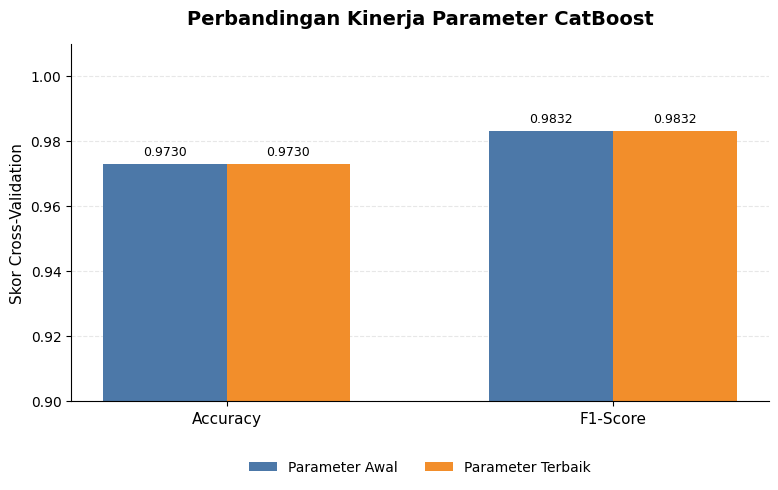

In [23]:

import matplotlib.pyplot as plt

# Ambil hasil konfigurasi awal dari Grid Search
baseline_row = grid_results_df[
    np.isclose(
        grid_results_df["learning_rate"],
        BASELINE_PARAMS["learning_rate"]
    )
    & (
        grid_results_df["depth"]
        == BASELINE_PARAMS["depth"]
    )
    & (
        grid_results_df["iterations"]
        == BASELINE_PARAMS["iterations"]
    )
].iloc[0]

# Susun tabel perbandingan
comparison_df = pd.DataFrame([
    {
        "Konfigurasi": "Parameter Awal",
        "Learning Rate": BASELINE_PARAMS["learning_rate"],
        "Depth": BASELINE_PARAMS["depth"],
        "Iterations": BASELINE_PARAMS["iterations"],
        "CV Accuracy": baseline_row["cv_accuracy_mean"],
        "CV Precision": baseline_row["cv_precision_mean"],
        "CV Recall": baseline_row["cv_recall_mean"],
        "CV F1-Score": baseline_row["cv_f1_mean"]
    },
    {
        "Konfigurasi": "Parameter Terbaik",
        "Learning Rate": best_params["learning_rate"],
        "Depth": best_params["depth"],
        "Iterations": best_params["iterations"],
        "CV Accuracy": best_row["cv_accuracy_mean"],
        "CV Precision": best_row["cv_precision_mean"],
        "CV Recall": best_row["cv_recall_mean"],
        "CV F1-Score": best_row["cv_f1_mean"]
    }
])

print("Tabel Perbandingan Parameter Awal dan Terbaik")
display(
    comparison_df.round(6)
)


# Visualisasi perbandingan Accuracy dan F1-Score
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FormatStrFormatter

metrics = ["Accuracy", "F1-Score"]
labels = ["Parameter Awal", "Parameter Terbaik"]

values = comparison_df[
    ["CV Accuracy", "CV F1-Score"]
].to_numpy()

x = np.arange(len(metrics))
width = 0.32

fig, ax = plt.subplots(figsize=(9, 5.5))

bars1 = ax.bar(
    x - width / 2, values[0], width,
    label=labels[0], color="#4C78A8"
)
bars2 = ax.bar(
    x + width / 2, values[1], width,
    label=labels[1], color="#F28E2B"
)

ax.set_title(
    "Perbandingan Kinerja Parameter CatBoost",
    fontsize=14, fontweight="bold", pad=14
)
ax.set_ylabel("Skor Cross-Validation", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=11)

ax.set_ylim(0.90, 1.01)
ax.set_yticks(np.arange(0.90, 1.001, 0.02))
ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.bar_label(bars1, fmt="%.4f", padding=4, fontsize=9)
ax.bar_label(bars2, fmt="%.4f", padding=4, fontsize=9)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=2,
    frameon=False
)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

fig.subplots_adjust(bottom=0.23, top=0.88)
plt.show()


## Buat Model Final

In [15]:
X_train_final = pd.read_csv(
    "../outputs/feature_integration/train_features.csv"
)

y_train_final = train_df[
    TARGET
].reset_index(drop=True)

assert X_train_final.shape == (
    64000,
    107
)

assert TARGET not in X_train_final.columns
assert len(y_train_final) == 64000

## Train CatBoost Final

In [16]:
final_model = CatBoostClassifier(

    learning_rate=
        best_params["learning_rate"],

    depth=
        best_params["depth"],

    iterations=
        best_params["iterations"],

    random_seed=42,

    boosting_type="Ordered",

    grow_policy="SymmetricTree",

    loss_function="Logloss",

    verbose=False,

    allow_writing_files=False,

    thread_count=-1
)

final_model.fit(

    X_train_final,

    y_train_final,

    cat_features=
        CATEGORICAL_FEATURES
)

print(
    "✅ Final CatBoost selesai."
)

print(
    "Jumlah data training:",
    len(X_train_final)
)

✅ Final CatBoost selesai.
Jumlah data training: 64000


## Simpan Model

In [17]:
MODEL_DIR = Path(
    "../models/catboost"
)

METRICS_DIR = Path(
    "../outputs/metrics"
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

final_model.save_model(
    MODEL_DIR /
    "catboost_final.cbm"
)

grid_results_df.to_csv(
    METRICS_DIR /
    "catboost_grid_search.csv",
    index=False
)

with open(
    METRICS_DIR /
    "catboost_best_params.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        best_params,
        f,
        indent=4
    )

print(
    "✅ Model dan hasil tuning tersimpan."
)

✅ Model dan hasil tuning tersimpan.


## Final Leakage Check

In [18]:
X_test_check = pd.read_csv(
    "../outputs/feature_integration/test_features.csv"
)

assert X_test_check.shape == (
    16000,
    107
)

assert TARGET not in X_test_check.columns

print("======================================")
print("CHECKPOINT 7 — FINAL CHECK")
print("======================================")

print(
    "TRAIN:",
    X_train_final.shape
)

print(
    "TEST :",
    X_test_check.shape
)

print(
    "CV   : 5-Fold"
)

print(
    "Grid Search:",
    len(grid_results_df),
    "kombinasi"
)

print("\nBest Parameters:")

for key, value in best_params.items():
    print(
        f"{key}: {value}"
    )

print("\nBest CV F1:",
      round(
          best_row["cv_f1_mean"],
          4
      ))

print("\nLeakage Check:")
print("✅ TEST tidak digunakan Grid Search")
print("✅ TEST tidak digunakan memilih parameter")
print("✅ KGE CV dibuat fold-specific")
print("✅ dev_status tidak menjadi feature")
print("✅ Final model dilatih menggunakan 64.000 TRAIN")
print("✅ TEST 16.000 disimpan untuk Evaluation")

print("\n✅ CHECKPOINT 7 SELESAI")

CHECKPOINT 7 — FINAL CHECK
TRAIN: (64000, 107)
TEST : (16000, 107)
CV   : 5-Fold
Grid Search: 18 kombinasi

Best Parameters:
learning_rate: 0.05
depth: 4
iterations: 200
random_seed: 42
boosting_type: Ordered
grow_policy: SymmetricTree
loss_function: Logloss

Best CV F1: 0.9832

Leakage Check:
✅ TEST tidak digunakan Grid Search
✅ TEST tidak digunakan memilih parameter
✅ KGE CV dibuat fold-specific
✅ dev_status tidak menjadi feature
✅ Final model dilatih menggunakan 64.000 TRAIN
✅ TEST 16.000 disimpan untuk Evaluation

✅ CHECKPOINT 7 SELESAI
